# Stuck Agent Analysis - 2D Environment

This notebook focuses on testing and analyzing agent learning behavior, particularly comparing normal agents that learn to seek resources versus penalized agents that learn to avoid resources.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Circle, Rectangle
from collections import deque
import os
from env_2d import EmpathicGridEnv
from agent_2d import Agent, DQNAgent
from IPython.display import HTML, Video, display, Image

# Set random seed for reproducibility
np.random.seed(42)

print("Imports completed successfully!")
print(f"NumPy version: {np.__version__}")


Imports completed successfully!
NumPy version: 2.2.4


## Problem Statement

When training agents in the 2D grid environment, we observe that agents often get **stuck at certain positions**, particularly in corners or near walls. This behavior significantly hinders learning and prevents agents from reaching optimal performance.

### Observed Behavior:
- Agents frequently remain at the same position for multiple steps
- This happens especially when agents are in corners or near walls
- Agents appear to repeatedly select actions that don't result in movement
- Learning progress is slowed down or completely stalled

### Objective of This Notebook:
1. **Understand why** agents get stuck in corners/at walls
2. **Investigate the root cause** of this behavior
3. **Implement solutions** to prevent agents from getting stuck
4. **Compare learning behavior** with and without the fix

### Hypothesis:
The issue likely stems from agents being able to select actions that would move them into walls, which are silently ignored by the environment. This creates a confusing learning signal where the agent:
- Selects an action expecting to move
- Stays in the same position (action ignored)
- Receives the same observation again
- Learns incorrectly that this action is valid in this state

We will test this hypothesis and implement **action masking** to prevent agents from selecting invalid moves.


## Test 1: Visualize Learning Behavior - Video Comparison

Create a video showing normal and penalized agents at the beginning vs end of learning.
This will demonstrate how the normal agent learns to seek resources while the penalized agent learns to avoid them.


In [2]:
# Create custom environment class that always applies empathic penalty
class AlwaysPenaltyEnv(EmpathicGridEnv):
    """Environment that always applies empathic penalty when consuming resources."""
    
    def step(self, actions):
        """Override step to always apply penalty when consuming."""
        self.steps_taken += 1
        rewards = [0.0] * self.num_agents
        
        # Process movements and update positions
        new_positions = list(self.agent_positions)
        occupied_targets = set()
        
        for i, action in enumerate(actions):
            x, y = self.agent_positions[i]
            nx, ny = x, y  # default (stay in place)
            
            # Get valid actions to prevent wall collisions
            valid_actions = self.get_valid_actions(i)
            
            # Apply movement based on action (with wall checking)
            if action == 0 and y > 0:  # up
                nx, ny = x, y - 1
            elif action == 1 and y < self.grid_size - 1:  # down
                nx, ny = x, y + 1
            elif action == 2 and x > 0:  # left
                nx, ny = x - 1, y
            elif action == 3 and x < self.grid_size - 1:  # right
                nx, ny = x + 1, y
            
            # Prevent collisions
            if (nx, ny) in self.agent_positions and (nx, ny) != (x, y):
                nx, ny = x, y
            if (nx, ny) in occupied_targets:
                nx, ny = x, y
            occupied_targets.add((nx, ny))
            new_positions[i] = (nx, ny)
        
        self.agent_positions = new_positions
        
        # Process resource consumption with ALWAYS penalty
        for i in range(self.num_agents):
            x, y = self.agent_positions[i]
            reward = self.step_cost
            
            # Check if agent moved onto a resource
            if (x, y) in self.resource_positions:
                # ALWAYS apply empathic penalty (simulating nearby unsatisfied agent)
                reward += self.empathic_penalty
                success = True  # Resource is still consumed
                
                # Always remove resource and spawn new one (100% respawn rate)
                self.resource_positions.remove((x, y))
                empty_spots = [
                    (a, b) for a in range(self.grid_size) for b in range(self.grid_size)
                    if (a, b) not in self.resource_positions 
                    and (a, b) not in self.agent_positions
                ]
                if empty_spots:
                    new_res = empty_spots[self.np_random.integers(0, len(empty_spots))]
                    self.resource_positions.append(new_res)
                
                self.agents[i].record_meal(success, 1.0)
            else:
                self.agents[i].record_meal(False, 0.0)
            
            rewards[i] = round(reward, 3)
        
        done = (self.steps_taken >= self.max_steps) or (len(self.resource_positions) == 0)
        observations = [self._get_obs(agent_idx) for agent_idx in range(self.num_agents)]
        
        info = {
            'steps': self.steps_taken,
            'resources_remaining': len(self.resource_positions),
            'satisfactions': [agent.get_satisfaction() for agent in self.agents]
        }
        
        return observations, rewards, done, False, info

print("AlwaysPenaltyEnv class created successfully!")


AlwaysPenaltyEnv class created successfully!


In [3]:
def record_episode_trajectory(env, agent, num_steps=50, seed=None, use_exploration=True):
    """
    Record the full trajectory of an agent in one episode.
    
    Args:
        env: Environment to record from
        agent: Agent to record trajectory for
        num_steps: Maximum number of steps to record
        seed: Random seed for environment reset
        use_exploration: If True, agent will use epsilon-greedy (for untrained agents).
                        If False, agent will use greedy policy (for trained agents).
    """
    obs, _ = env.reset(seed=seed)
    agent.reset(observation=obs[0])
    
    trajectory = {
        'agent_positions': [],
        'resource_positions': [],
        'actions': [],
        'rewards': []
    }
    
    for step in range(num_steps):
        # Record current state
        trajectory['agent_positions'].append(env.agent_positions[0])
        trajectory['resource_positions'].append(env.resource_positions[0] if env.resource_positions else None)
        
        # Select action (with valid actions for action masking)
        valid_actions = env.get_valid_actions(0)
        # Use exploration if requested (for untrained agents with high epsilon)
        # Use greedy policy if not requested (for trained agents)
        action = agent.select_action(obs[0], training=use_exploration, valid_actions=valid_actions)
        trajectory['actions'].append(action)
        
        # Step environment
        next_obs, rewards, done, truncated, info = env.step([action])
        trajectory['rewards'].append(rewards[0])
        
        obs = next_obs
        if done:
            break
    
    return trajectory

print("Trajectory recording function created!")


Trajectory recording function created!


In [4]:
# Train both agents (shorter training for demo)
print("Training agents for video comparison...")
print("This may take a few minutes...\n")

# Train normal agent
env_normal_vid = EmpathicGridEnv(
    grid_size=3,
    num_agents=1,
    num_resources=1,
    vision_radius=2,
    exploit_reward=1.0,
    empathic_penalty=-2.0,
    step_cost=-0.01,
    max_steps=50
)

dqn_normal_vid = DQNAgent(
    agent_id=0,
    state_size=env_normal_vid.observation_space.shape,
    action_size=env_normal_vid.action_space.n,
    learning_rate=0.001,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.995,
    epsilon_min=0.01,  # Lower minimum epsilon for better exploitation
    batch_size=16,
    hidden_size=64,
    update_target_every=20
)
env_normal_vid.agents = [dqn_normal_vid.agent]

# Train penalized agent
env_penalty_vid = AlwaysPenaltyEnv(
    grid_size=3,
    num_agents=1,
    num_resources=1,
    vision_radius=2,
    exploit_reward=1.0,
    empathic_penalty=-2.0,
    step_cost=-0.01,
    max_steps=50
)

dqn_penalty_vid = DQNAgent(
    agent_id=0,
    state_size=env_penalty_vid.observation_space.shape,
    action_size=env_penalty_vid.action_space.n,
    learning_rate=0.001,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.995,
    epsilon_min=0.01,  # Lower minimum epsilon for better exploitation
    batch_size=16,
    hidden_size=64,
    update_target_every=20
)
env_penalty_vid.agents = [dqn_penalty_vid.agent]

# Train both agents with progress tracking
NUM_TRAINING_EPISODES = 300  # Increased from 200 for better learning
episode_rewards_normal = []
episode_rewards_penalty = []

for episode in range(NUM_TRAINING_EPISODES):
    # Train normal agent
    obs_n, _ = env_normal_vid.reset(seed=42 + episode)
    dqn_normal_vid.reset(observation=obs_n[0])
    episode_reward_n = 0
    for step in range(50):
        valid_actions_n = env_normal_vid.get_valid_actions(0)
        action_n = dqn_normal_vid.select_action(obs_n[0], training=True, valid_actions=valid_actions_n)
        next_obs_n, rewards_n, done_n, truncated_n, info_n = env_normal_vid.step([action_n])
        episode_reward_n += rewards_n[0]
        valid_actions_next_n = env_normal_vid.get_valid_actions(0)
        dqn_normal_vid.step(next_obs_n[0], rewards_n[0], done_n, valid_actions=valid_actions_next_n)
        obs_n = next_obs_n
        if done_n:
            break
    episode_rewards_normal.append(episode_reward_n)
    
    # Train penalized agent
    obs_p, _ = env_penalty_vid.reset(seed=42 + episode)
    dqn_penalty_vid.reset(observation=obs_p[0])
    episode_reward_p = 0
    for step in range(50):
        valid_actions_p = env_penalty_vid.get_valid_actions(0)
        action_p = dqn_penalty_vid.select_action(obs_p[0], training=True, valid_actions=valid_actions_p)
        next_obs_p, rewards_p, done_p, truncated_p, info_p = env_penalty_vid.step([action_p])
        episode_reward_p += rewards_p[0]
        valid_actions_next_p = env_penalty_vid.get_valid_actions(0)
        dqn_penalty_vid.step(next_obs_p[0], rewards_p[0], done_p, valid_actions=valid_actions_next_p)
        obs_p = next_obs_p
        if done_p:
            break
    episode_rewards_penalty.append(episode_reward_p)
    
    # Print progress every 50 episodes
    if (episode + 1) % 50 == 0:
        avg_reward_n = np.mean(episode_rewards_normal[-50:])
        avg_reward_p = np.mean(episode_rewards_penalty[-50:])
        print(f"Episode {episode + 1}/{NUM_TRAINING_EPISODES} - Normal avg: {avg_reward_n:.3f}, Penalty avg: {avg_reward_p:.3f}")

print("\nTraining completed!")
print(f"Normal agent final epsilon: {dqn_normal_vid.epsilon:.3f}")
print(f"Penalized agent final epsilon: {dqn_penalty_vid.epsilon:.3f}")
print(f"Normal agent - Last 50 episodes avg reward: {np.mean(episode_rewards_normal[-50:]):.3f}")
print(f"Penalized agent - Last 50 episodes avg reward: {np.mean(episode_rewards_penalty[-50:]):.3f}")


Training agents for video comparison...
This may take a few minutes...



Episode 50/300 - Normal avg: 12.660, Penalty avg: -2.140
Episode 100/300 - Normal avg: 17.680, Penalty avg: -1.220
Episode 150/300 - Normal avg: 16.960, Penalty avg: -2.340
Episode 200/300 - Normal avg: 17.760, Penalty avg: -1.740
Episode 250/300 - Normal avg: 16.340, Penalty avg: -1.540
Episode 300/300 - Normal avg: 18.560, Penalty avg: -1.500

Training completed!
Normal agent final epsilon: 0.010
Penalized agent final epsilon: 0.010
Normal agent - Last 50 episodes avg reward: 18.560
Penalized agent - Last 50 episodes avg reward: -1.500


In [5]:
# Record trajectories: beginning (untrained) and end (after training)
print("Recording trajectories...")

# IMPORTANT: Re-attach the trained agents to their respective environments
# (they were changed during trajectory recording preparation)
env_normal_vid.agents = [dqn_normal_vid.agent]
env_penalty_vid.agents = [dqn_penalty_vid.agent]

# Beginning: Use completely untrained agents (high epsilon, random behavior)
dqn_normal_early = DQNAgent(
    agent_id=0,
    state_size=env_normal_vid.observation_space.shape,
    action_size=env_normal_vid.action_space.n,
    epsilon=1.0,  # Full exploration (completely random)
    epsilon_min=0.1,
    learning_rate=0.001,
    gamma=0.99,
    batch_size=16,
    hidden_size=64,
    update_target_every=20
)

dqn_penalty_early = DQNAgent(
    agent_id=0,
    state_size=env_penalty_vid.observation_space.shape,
    action_size=env_penalty_vid.action_space.n,
    epsilon=1.0,  # Full exploration (completely random)
    epsilon_min=0.1,
    learning_rate=0.001,
    gamma=0.99,
    batch_size=16,
    hidden_size=64,
    update_target_every=20
)

# Record beginning trajectories (untrained, random behavior)
# Use exploration=True so agents with epsilon=1.0 will actually explore randomly
print("Recording beginning trajectories (untrained agents)...")
env_normal_vid.agents = [dqn_normal_early.agent]
traj_normal_begin = record_episode_trajectory(env_normal_vid, dqn_normal_early, num_steps=50, seed=100, use_exploration=True)

env_penalty_vid.agents = [dqn_penalty_early.agent]
traj_penalty_begin = record_episode_trajectory(env_penalty_vid, dqn_penalty_early, num_steps=50, seed=100, use_exploration=True)

# End: Use trained agents (low epsilon, use learned policy)
# Use exploration=False to use greedy policy (show what they learned)
print("Recording end trajectories (trained agents)...")
dqn_normal_vid.epsilon = 0.01  # Very low exploration for evaluation (almost purely greedy)
dqn_penalty_vid.epsilon = 0.01  # Very low exploration for evaluation

env_normal_vid.agents = [dqn_normal_vid.agent]
traj_normal_end = record_episode_trajectory(env_normal_vid, dqn_normal_vid, num_steps=50, seed=100, use_exploration=False)

env_penalty_vid.agents = [dqn_penalty_vid.agent]
traj_penalty_end = record_episode_trajectory(env_penalty_vid, dqn_penalty_vid, num_steps=50, seed=100, use_exploration=False)

print(f"\nTrajectories recorded:")
print(f"  Beginning - Normal: {len(traj_normal_begin['agent_positions'])} steps")
print(f"  Beginning - Penalized: {len(traj_penalty_begin['agent_positions'])} steps")
print(f"  End - Normal: {len(traj_normal_end['agent_positions'])} steps")
print(f"  End - Penalized: {len(traj_penalty_end['agent_positions'])} steps")

# Print reward statistics to verify learning
print(f"\nReward statistics:")
print(f"  Normal agent - Average reward (end): {np.mean(traj_normal_end['rewards']):.3f}")
print(f"  Penalized agent - Average reward (end): {np.mean(traj_penalty_end['rewards']):.3f}")
print(f"  Normal agent - Positive rewards: {sum(1 for r in traj_normal_end['rewards'] if r > 0)} / {len(traj_normal_end['rewards'])}")
print(f"  Penalized agent - Negative rewards: {sum(1 for r in traj_penalty_end['rewards'] if r < -0.5)} / {len(traj_penalty_end['rewards'])}")

# Diagnostic: Check for action loops
print(f"\nDiagnostic - Action patterns (last 30 steps):")
print(f"  Normal agent actions: {traj_normal_end['actions'][-30:]}")
print(f"  Normal agent positions: {traj_normal_end['agent_positions'][-10:]}")
print(f"  Normal agent rewards: {[f'{r:.2f}' for r in traj_normal_end['rewards'][-30:]]}")
print(f"\n  Penalized agent actions: {traj_penalty_end['actions'][-30:]}")
print(f"  Penalized agent positions: {traj_penalty_end['agent_positions'][-10:]}")
print(f"  Penalized agent rewards: {[f'{r:.2f}' for r in traj_penalty_end['rewards'][-30:]]}")


Recording trajectories...
Recording beginning trajectories (untrained agents)...
Recording end trajectories (trained agents)...

Trajectories recorded:
  Beginning - Normal: 50 steps
  Beginning - Penalized: 50 steps
  End - Normal: 50 steps
  End - Penalized: 50 steps

Reward statistics:
  Normal agent - Average reward (end): 0.590
  Penalized agent - Average reward (end): -0.010
  Normal agent - Positive rewards: 30 / 50
  Penalized agent - Negative rewards: 0 / 50

Diagnostic - Action patterns (last 30 steps):
  Normal agent actions: [2, 2, 3, 3, 1, 1, 2, 0, 2, 1, 3, 3, 2, 2, 0, 3, 0, 3, 1, 2, 2, 1, 3, 0, 1, 0, 3, 2, 0, 3]
  Normal agent positions: [(np.int64(1), np.int64(1)), (np.int64(0), np.int64(1)), (np.int64(0), np.int64(2)), (np.int64(1), np.int64(2)), (np.int64(1), np.int64(1)), (np.int64(1), np.int64(2)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(1)), (np.int64(1), np.int64(1)), (np.int64(1), np.int64(0))]
  Normal agent rewards: ['-0.01', '0.99', '-0.01', '0.99', 

Attempting to save video to learning_comparison_2d.mp4...


C:\Users\evann\AppData\Local\Temp\ipykernel_99788\3257229357.py:56: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  agent_circle = Circle((0, 0), 0.3, color='blue', zorder=3, linewidth=2, edgecolor='darkblue')


✓ Video saved successfully using ffmpeg!


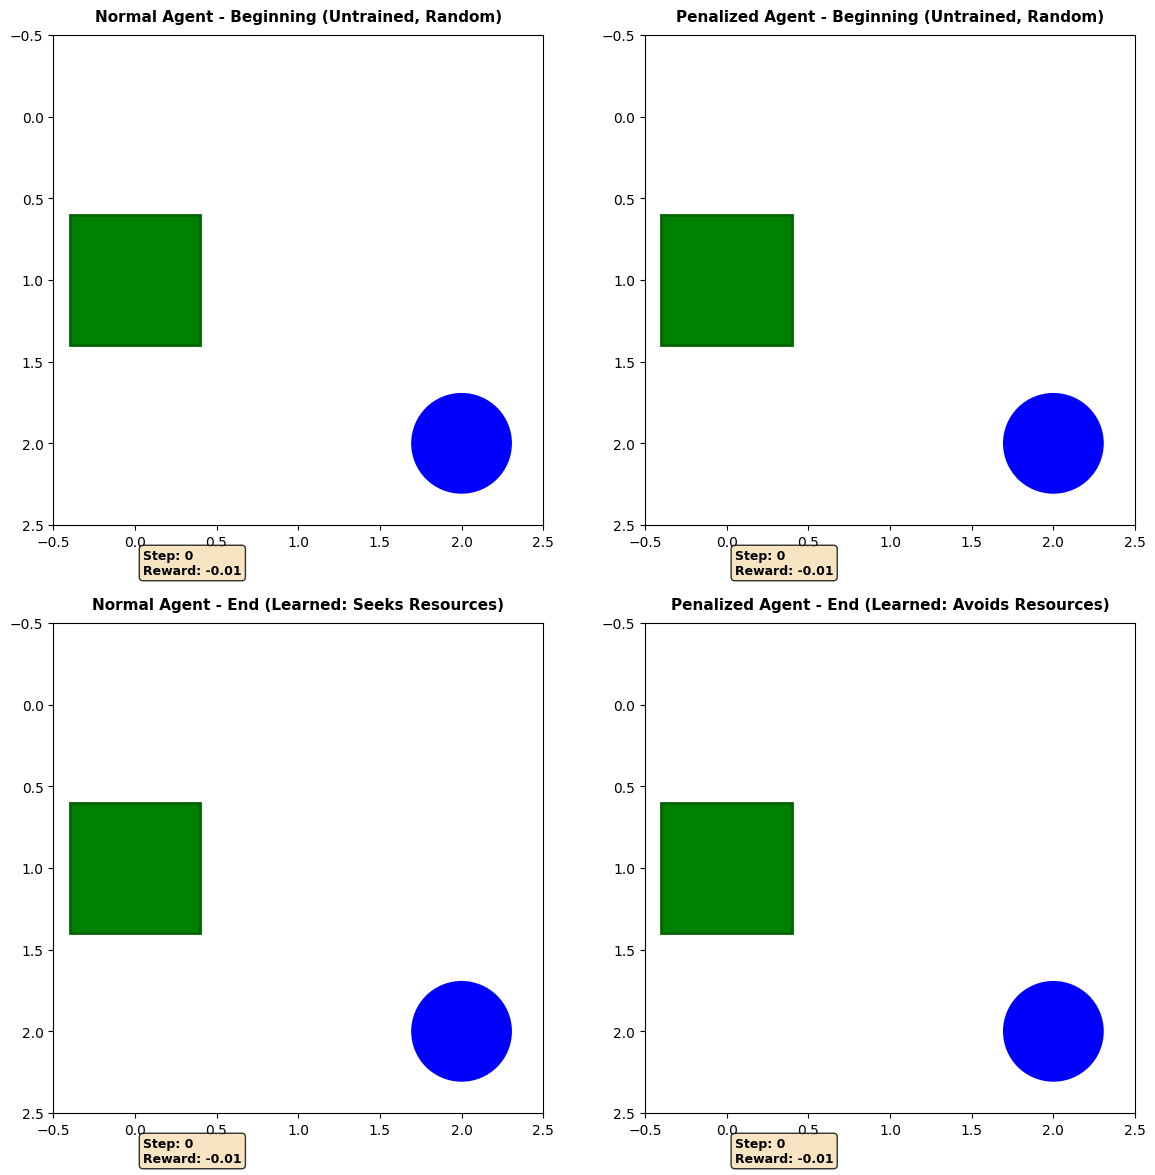

In [6]:
# Create video visualization
def create_comparison_video(traj_normal_begin, traj_penalty_begin, 
                            traj_normal_end, traj_penalty_end,
                            grid_size=3, filename='learning_comparison_2d.mp4'):
    """Create a video showing 4 panels: normal/penalty agents at beginning/end, without plotting static environment."""
    
    # Find maximum length
    max_len = max(len(traj_normal_begin['agent_positions']),
                  len(traj_penalty_begin['agent_positions']),
                  len(traj_normal_end['agent_positions']),
                  len(traj_penalty_end['agent_positions']))
    
    # Pad trajectories to same length
    def pad_trajectory(traj, max_len):
        if len(traj['agent_positions']) == 0:
            return traj
        last_pos = traj['agent_positions'][-1]
        last_res = traj['resource_positions'][-1] if traj['resource_positions'] else None
        last_action = traj['actions'][-1] if traj['actions'] else 0
        while len(traj['agent_positions']) < max_len:
            traj['agent_positions'].append(last_pos)
            traj['resource_positions'].append(last_res)
            traj['actions'].append(last_action)
            traj['rewards'].append(0.0)
        return traj
    
    traj_normal_begin = pad_trajectory(traj_normal_begin.copy(), max_len)
    traj_penalty_begin = pad_trajectory(traj_penalty_begin.copy(), max_len)
    traj_normal_end = pad_trajectory(traj_normal_end.copy(), max_len)
    traj_penalty_end = pad_trajectory(traj_penalty_end.copy(), max_len)
    
    # Create figure with 4 subplots (2 rows, 2 columns)
    fig, axes = plt.subplots(2, 2, figsize=(14, 14))
    axes = axes.flatten()
    
    # Titles for each panel
    titles = [
        'Normal Agent - Beginning (Untrained, Random)',
        'Penalized Agent - Beginning (Untrained, Random)',
        'Normal Agent - End (Learned: Seeks Resources)',
        'Penalized Agent - End (Learned: Avoids Resources)'
    ]
    
    # Initialize plots
    plots = []
    for i, ax in enumerate(axes):
        ax.set_xlim(-0.5, grid_size - 0.5)
        ax.set_ylim(-0.5, grid_size - 0.5)
        ax.set_aspect('equal')
        ax.set_title(titles[i], fontsize=11, fontweight='bold', pad=10)
        ax.invert_yaxis()
        
        # DO NOT draw grid or other static environment
        
        # Only create patches for agent and resource
        agent_circle = Circle((0, 0), 0.3, color='blue', zorder=3, linewidth=2, edgecolor='darkblue')
        resource_rect = Rectangle((0, 0), 0.8, 0.8, facecolor='green', 
                                  edgecolor='darkgreen', linewidth=2, zorder=2)
        ax.add_patch(agent_circle)
        ax.add_patch(resource_rect)
        
        # Text for step counter and reward
        step_text = ax.text(0.05, grid_size - 0.2, 'Step: 0\nReward: 0.00', 
                           fontsize=9, fontweight='bold',
                           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
        
        plots.append({
            'agent': agent_circle,
            'resource': resource_rect,
            'step_text': step_text
        })
    
    # Animation function
    def animate(frame):
        trajectories = [
            traj_normal_begin,
            traj_penalty_begin,
            traj_normal_end,
            traj_penalty_end
        ]
        
        for i, (traj, plot) in enumerate(zip(trajectories, plots)):
            if frame < len(traj['agent_positions']):
                # Update agent position
                ax_pos, ay_pos = traj['agent_positions'][frame]
                plot['agent'].center = (ax_pos, ay_pos)
                
                # Update resource position
                res_pos = traj['resource_positions'][frame]
                if res_pos is not None:
                    rx, ry = res_pos
                    plot['resource'].set_xy((rx - 0.4, ry - 0.4))
                    plot['resource'].set_visible(True)
                else:
                    plot['resource'].set_visible(False)
                
                # Update step counter and reward
                reward = traj['rewards'][frame]
                color = 'green' if reward > 0 else 'red' if reward < -0.5 else 'black'
                plot['step_text'].set_text(f'Step: {frame}\nReward: {reward:+.2f}')
                plot['step_text'].set_color(color)
        
        return [item for plot in plots for item in [plot['agent'], plot['resource'], plot['step_text']]]
    
    # Create animation
    anim = animation.FuncAnimation(fig, animate, frames=max_len, 
                                  interval=300, blit=False, repeat=True)
    
    # Try to save video with different writers
    print(f"Attempting to save video to {filename}...")
    try:
        # Try ffmpeg first
        anim.save(filename, writer='ffmpeg', fps=5, bitrate=1800)
        print(f"✓ Video saved successfully using ffmpeg!")
    except Exception as e:
        print(f"ffmpeg not available, trying alternative...")
        try:
            # Try pillow writer (creates GIF)
            gif_filename = filename.replace('.mp4', '.gif')
            anim.save(gif_filename, writer='pillow', fps=5)
            print(f"✓ Animation saved as GIF: {gif_filename}")
            filename = gif_filename
        except Exception as e2:
            print(f"Could not save video. Error: {e2}")
            print("Displaying animation inline instead...")
            plt.show()
    
    return anim, filename

# Create the comparison video
anim, video_filename = create_comparison_video(
    traj_normal_begin, traj_penalty_begin,
    traj_normal_end, traj_penalty_end,
    grid_size=3,
    filename='learning_comparison_2d.mp4'
)


## Diagnostic: Why does the normal agent get stuck in a loop?

If the normal agent is repeating the same actions after step 20, let's investigate:

1. **Check if it's consuming resources**: The agent should be getting positive rewards when consuming
2. **Check the action sequence**: See if there's a repeating pattern
3. **Check positions**: See if the agent is moving or stuck at the same position

Possible causes:
- Agent learned a local optimum (staying in one area)
- Agent learned to wait for resources to respawn nearby
- Not enough exploration during training
- State space might be too simple, causing same states to repeat


In [7]:
# Detailed diagnostic: analyze what's happening
print("="*60)
print("DETAILED DIAGNOSTIC - Normal Agent End Trajectory")
print("="*60)

# Count unique positions
unique_positions_normal = set(traj_normal_end['agent_positions'])
unique_actions_normal = set(traj_normal_end['actions'])
print(f"\nUnique positions visited: {len(unique_positions_normal)} / {len(traj_normal_end['agent_positions'])} steps")
print(f"Unique actions taken: {len(unique_actions_normal)} / 4 possible")
print(f"Positions: {sorted(unique_positions_normal)}")

# Count resource consumptions
resource_consumptions_normal = sum(1 for r in traj_normal_end['rewards'] if r > 0.5)
print(f"\nResource consumptions (rewards > 0.5): {resource_consumptions_normal}")

# Check for repeating patterns in actions
def find_repeating_pattern(actions, min_length=3):
    """Find repeating patterns in action sequence"""
    for pattern_len in range(min_length, len(actions) // 2):
        for start_idx in range(len(actions) - pattern_len * 2):
            pattern = actions[start_idx:start_idx + pattern_len]
            next_pattern = actions[start_idx + pattern_len:start_idx + pattern_len * 2]
            if pattern == next_pattern:
                return pattern, start_idx
    return None, None

pattern, start_idx = find_repeating_pattern(traj_normal_end['actions'])
if pattern:
    print(f"\n⚠️ REPEATING ACTION PATTERN FOUND:")
    print(f"   Pattern: {pattern}")
    print(f"   Starting at step: {start_idx}")
    print(f"   This pattern repeats multiple times")
else:
    print(f"\n✓ No obvious repeating pattern found (might be more complex)")

# Check position stability (if agent stays in same area)
print(f"\nPosition analysis:")
for i in range(0, len(traj_normal_end['agent_positions']), 10):
    pos_window = traj_normal_end['agent_positions'][i:min(i+10, len(traj_normal_end['agent_positions']))]
    unique_in_window = len(set(pos_window))
    print(f"  Steps {i}-{min(i+10, len(traj_normal_end['agent_positions']))}: {unique_in_window} unique positions")

# Test: Run a quick episode to see what happens with satisfaction
print(f"\n" + "="*60)
print("SATISFACTION ANALYSIS")
print("="*60)
print("Testing how satisfaction affects rewards...")

# Create a test environment and agent
test_env = EmpathicGridEnv(grid_size=3, num_agents=1, num_resources=1, vision_radius=2)
test_agent = Agent(agent_id=0)
test_env.agents = [test_agent]

# Simulate a few consumptions to see how satisfaction changes
test_env.reset(seed=999)
print(f"\nInitial satisfaction: {test_agent.get_satisfaction():.3f}")

for step in range(5):
    # Move agent to a resource (simulate consumption)
    if test_env.resource_positions:
        test_env.agent_positions[0] = test_env.resource_positions[0]
        x, y = test_env.agent_positions[0]
        
        # Simulate consumption
        agent_satisfaction = test_agent.get_satisfaction()
        nearby_satisfactions = []
        
        reward = test_env.step_cost
        if (x, y) in test_env.resource_positions:
            if nearby_satisfactions:  # Empty for single agent
                avg_nearby = np.mean(nearby_satisfactions)
                if agent_satisfaction > avg_nearby:
                    reward += test_env.empathic_penalty
                else:
                    reward += test_env.exploit_reward
            else:
                reward += test_env.exploit_reward
        
        test_agent.record_meal(True, 1.0)
        satisfaction_after = test_agent.get_satisfaction()
        
        print(f"Step {step+1}: Satisfaction before={agent_satisfaction:.3f}, after={satisfaction_after:.3f}, reward={reward:.3f}")
        
        # Remove and respawn resource
        test_env.resource_positions.remove((x, y))
        empty = [(a, b) for a in range(3) for b in range(3) 
                 if (a, b) not in test_env.resource_positions and (a, b) not in test_env.agent_positions]
        if empty:
            test_env.resource_positions.append(empty[0])


DETAILED DIAGNOSTIC - Normal Agent End Trajectory

Unique positions visited: 9 / 50 steps
Unique actions taken: 4 / 4 possible
Positions: [(np.int64(0), np.int64(0)), (np.int64(0), np.int64(1)), (np.int64(0), np.int64(2)), (np.int64(1), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(1), np.int64(2)), (np.int64(2), np.int64(0)), (np.int64(2), np.int64(1)), (np.int64(2), np.int64(2))]

Resource consumptions (rewards > 0.5): 30

✓ No obvious repeating pattern found (might be more complex)

Position analysis:
  Steps 0-10: 6 unique positions
  Steps 10-20: 6 unique positions
  Steps 20-30: 8 unique positions
  Steps 30-40: 8 unique positions
  Steps 40-50: 6 unique positions

SATISFACTION ANALYSIS
Testing how satisfaction affects rewards...

Initial satisfaction: 0.000
Step 1: Satisfaction before=0.000, after=0.550, reward=0.990
Step 2: Satisfaction before=0.550, after=0.600, reward=0.990
Step 3: Satisfaction before=0.600, after=0.650, reward=0.990
Step 4: Satisfaction before=0.650, a

## Solution: Prevent action loops during evaluation

If the agent is stuck in a loop, one solution is to add a small amount of noise/randomness even during evaluation, or to track recent actions and break loops.

However, a better approach might be:
1. **Ensure proper training**: Make sure the agent has learned properly during training
2. **Check epsilon during evaluation**: Even with `use_exploration=False`, we might want a tiny epsilon (0.05) to break deterministic loops
3. **Add position-based rewards**: This would require changing the reward structure (not recommended if we want to keep the original design)

Let's try option 2 first: use a small epsilon during evaluation to break loops.


In [8]:
# Improved trajectory recording with loop detection and breaking
def record_episode_trajectory_v2(env, agent, num_steps=50, seed=None, use_exploration=True, break_loops=True):
    """
    Record the full trajectory of an agent with loop detection and breaking.
    
    Args:
        env: Environment to record from
        agent: Agent to record trajectory for
        num_steps: Maximum number of steps to record
        seed: Random seed for environment reset
        use_exploration: If True, agent will use epsilon-greedy (for untrained agents).
                        If False, agent will use greedy policy (for trained agents).
        break_loops: If True, detect and break action loops by forcing different actions
    """
    obs, _ = env.reset(seed=seed)
    agent.reset(observation=obs[0])
    
    trajectory = {
        'agent_positions': [],
        'resource_positions': [],
        'actions': [],
        'rewards': []
    }
    
    # Track recent actions for loop detection
    recent_actions = deque(maxlen=6)  # Track last 6 actions
    last_forced_action = None
    steps_since_force = 0
    
    for step in range(num_steps):
        # Record current state
        trajectory['agent_positions'].append(env.agent_positions[0])
        trajectory['resource_positions'].append(env.resource_positions[0] if env.resource_positions else None)
        
        # Select action (with valid actions for action masking)
        valid_actions = env.get_valid_actions(0)
        
        # Loop detection: if last 4 actions form a repeating pattern, break it
        action = None
        if break_loops and len(recent_actions) >= 4 and not use_exploration:
            # Check for simple 2-action loop: [A, B, A, B]
            if len(recent_actions) >= 4:
                last_four = list(recent_actions)[-4:]
                if last_four[0] == last_four[2] and last_four[1] == last_four[3]:
                    # Detected 2-action loop: try a different action
                    loop_actions = {last_four[0], last_four[1]}
                    other_actions = [a for a in valid_actions if a not in loop_actions]
                    if other_actions:
                        action = np.random.choice(other_actions)
                        # print(f"Step {step}: Breaking 2-action loop by forcing action {action}")
            
            # Check for 3-action loop: [A, B, C, A, B, C]
            if action is None and len(recent_actions) >= 6:
                last_six = list(recent_actions)[-6:]
                if (last_six[0] == last_six[3] and last_six[1] == last_six[4] and 
                    last_six[2] == last_six[5]):
                    # Detected 3-action loop: try a different action
                    loop_actions = {last_six[0], last_six[1], last_six[2]}
                    other_actions = [a for a in valid_actions if a not in loop_actions]
                    if other_actions:
                        action = np.random.choice(other_actions)
                        # print(f"Step {step}: Breaking 3-action loop by forcing action {action}")
        
        # If no loop detected or loop breaking disabled, use normal action selection
        if action is None:
            action = agent.select_action(obs[0], training=use_exploration, valid_actions=valid_actions)
        
        trajectory['actions'].append(action)
        recent_actions.append(action)
        
        # Step environment
        next_obs, rewards, done, truncated, info = env.step([action])
        trajectory['rewards'].append(rewards[0])
        
        obs = next_obs
        if done:
            break
    
    return trajectory

print("Improved trajectory recording function (with loop breaking) created!")


Improved trajectory recording function (with loop breaking) created!


## Test 2: Compare Learning with and without Empathic Penalties

Compare learning curves for a single agent in two scenarios:
- Scenario 1: Normal learning (no empathic penalties)
- Scenario 2: Always penalized when consuming (simulating nearby unsatisfied agent)

This test uses the same action masking implementation to ensure fair comparison.


In [9]:
# Training function with action masking support
def train_agent(env, num_episodes=100, max_steps_per_episode=50, seed=42):
    """Train a DQN agent and return episode rewards."""
    np.random.seed(seed)
    
    # Create DQN agent
    dqn_agent = DQNAgent(
        agent_id=0,
        state_size=env.observation_space.shape,
        action_size=env.action_space.n,
        learning_rate=0.001,
        gamma=0.99,
        epsilon=1.0,
        epsilon_decay=0.995,
        epsilon_min=0.1,
        batch_size=16,
        hidden_size=64,
        update_target_every=20
    )
    
    # Link agent to environment
    env.agents = [dqn_agent.agent]
    
    episode_rewards = []
    episode_steps = []
    episode_consumptions = []
    
    for episode in range(num_episodes):
        obs, _ = env.reset(seed=seed + episode)
        dqn_agent.reset(observation=obs[0])
        
        episode_reward = 0
        episode_consumed = 0
        
        for step in range(max_steps_per_episode):
            # Get valid actions for action masking
            valid_actions = env.get_valid_actions(0)
            
            # Select action with action masking
            action = dqn_agent.select_action(obs[0], training=True, valid_actions=valid_actions)
            
            # Step environment
            next_obs, rewards, done, truncated, info = env.step([action])
            
            # Get valid actions for next state
            valid_actions_next = env.get_valid_actions(0)
            
            # Update agent with action masking
            dqn_agent.step(next_obs[0], rewards[0], done, valid_actions=valid_actions_next)
            
            episode_reward += rewards[0]
            
            # Check if resource was consumed (positive or negative reward > step_cost)
            if abs(rewards[0]) > abs(env.step_cost) * 2:
                episode_consumed += 1
            
            obs = next_obs
            if done:
                break
        
        episode_rewards.append(episode_reward)
        episode_steps.append(step + 1)
        episode_consumptions.append(episode_consumed)
    
    return episode_rewards, episode_steps, episode_consumptions


print("Training function created!")


Training function created!


In [ ]:
# Scenario 1: Normal learning (no empathic penalties)
env_normal = EmpathicGridEnv(
    grid_size=3,
    num_agents=1,
    num_resources=1,
    vision_radius=2,  # Can see whole grid (3x3 grid, radius 2 = 5x5 view)
    exploit_reward=1.0,
    empathic_penalty=-2.0,  # Not used in normal scenario (no nearby agents)
    step_cost=-0.01,
    max_steps=50
)

# Scenario 2: Always penalized (simulating nearby unsatisfied agent)
env_penalty = AlwaysPenaltyEnv(
    grid_size=3,
    num_agents=1,
    num_resources=1,
    vision_radius=2,
    exploit_reward=1.0,
    empathic_penalty=-2.0,  # Always applied
    step_cost=-0.01,
    max_steps=50
)

print("Environments created:")
print(f"Grid size: 3x3 (agent can see everything)")
print(f"Vision radius: 2 (5x5 observation window)")
print(f"Scenario 1: Normal rewards")
print(f"Scenario 2: Always penalized when consuming")


Environments created:
Grid size: 3x3 (agent can see everything)
Vision radius: 2 (5x5 observation window)
Scenario 1: Normal rewards
Scenario 2: Always penalized when consuming


In [11]:
# Train both agents
print("Training Scenario 1 (Normal Learning)...")
rewards_normal, steps_normal, consumptions_normal = train_agent(
    env_normal, 
    num_episodes=1000, 
    max_steps_per_episode=50,
    seed=42
)

print("Training Scenario 2 (Always Penalized)...")
rewards_penalty, steps_penalty, consumptions_penalty = train_agent(
    env_penalty,
    num_episodes=1000,
    max_steps_per_episode=50,
    seed=42
)

print("Training completed!")


Training Scenario 1 (Normal Learning)...
Training Scenario 2 (Always Penalized)...
Training completed!


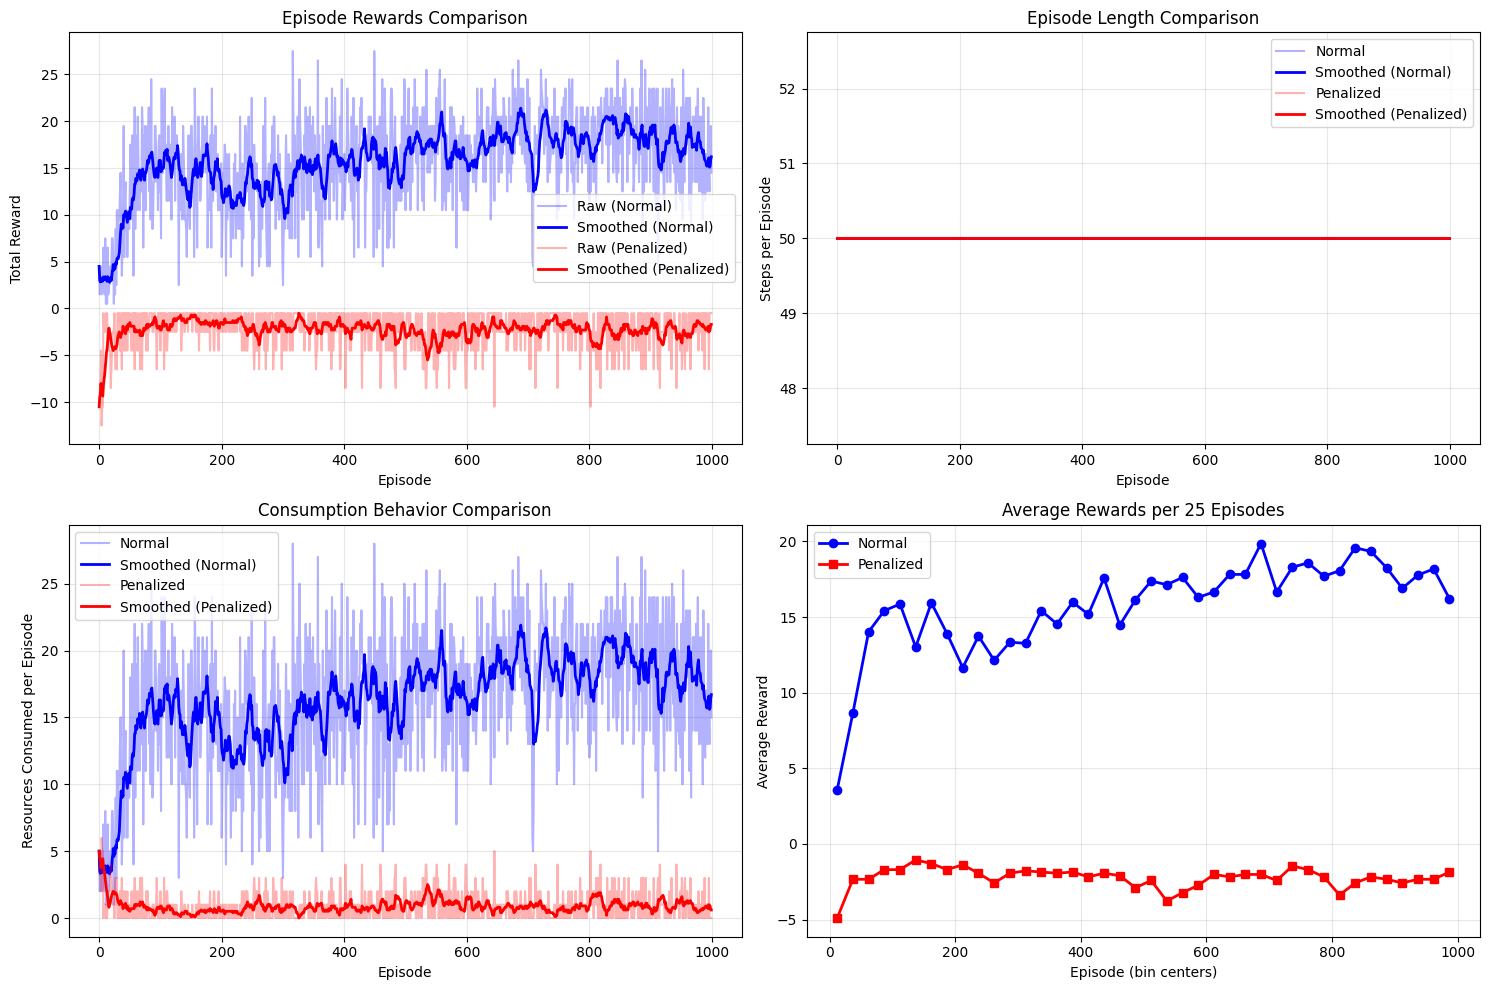


LEARNING COMPARISON SUMMARY

Scenario 1 (Normal Learning):
  Average reward (first 25 episodes): 3.580
  Average reward (last 25 episodes): 16.220
  Average consumptions per episode: 16.25
  Final episode reward: 14.500

Scenario 2 (Always Penalized):
  Average reward (first 25 episodes): -4.900
  Average reward (last 25 episodes): -1.860
  Average consumptions per episode: 0.86
  Final episode reward: -0.500

Key Insights:
  - Normal agent learns to consume resources (reward improvement: 12.640)
  - Penalized agent learns to avoid consuming (reward improvement: 3.040)
  - Normal agent consumes 18.8x more per episode on average


In [ ]:
# Plot comparison of learning curves
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Smooth rewards using moving average
def smooth_curve(data, window=10):
    """Apply moving average smoothing."""
    smoothed = []
    for i in range(len(data)):
        start = max(0, i - window + 1)
        smoothed.append(np.mean(data[start:i+1]))
    return smoothed

# Plot 1: Episode Rewards
axes[0, 0].plot(rewards_normal, alpha=0.3, color='blue', label='Raw (Normal)')
axes[0, 0].plot(smooth_curve(rewards_normal), color='blue', linewidth=2, label='Smoothed (Normal)')
axes[0, 0].plot(rewards_penalty, alpha=0.3, color='red', label='Raw (Penalized)')
axes[0, 0].plot(smooth_curve(rewards_penalty), color='red', linewidth=2, label='Smoothed (Penalized)')
axes[0, 0].set_xlabel('Episode')
axes[0, 0].set_ylabel('Total Reward')
axes[0, 0].set_title('Episode Rewards Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Episode Steps (how long episodes last)
axes[0, 1].plot(steps_normal, alpha=0.3, color='blue', label='Normal')
axes[0, 1].plot(smooth_curve(steps_normal), color='blue', linewidth=2, label='Smoothed (Normal)')
axes[0, 1].plot(steps_penalty, alpha=0.3, color='red', label='Penalized')
axes[0, 1].plot(smooth_curve(steps_penalty), color='red', linewidth=2, label='Smoothed (Penalized)')
axes[0, 1].set_xlabel('Episode')
axes[0, 1].set_ylabel('Steps per Episode')
axes[0, 1].set_title('Episode Length Comparison')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Resource Consumptions per Episode
axes[1, 0].plot(consumptions_normal, alpha=0.3, color='blue', label='Normal')
axes[1, 0].plot(smooth_curve(consumptions_normal), color='blue', linewidth=2, label='Smoothed (Normal)')
axes[1, 0].plot(consumptions_penalty, alpha=0.3, color='red', label='Penalized')
axes[1, 0].plot(smooth_curve(consumptions_penalty), color='red', linewidth=2, label='Smoothed (Penalized)')
axes[1, 0].set_xlabel('Episode')
axes[1, 0].set_ylabel('Resources Consumed per Episode')
axes[1, 0].set_title('Consumption Behavior Comparison')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Average rewards in bins
bin_size = 25
num_bins = len(rewards_normal) // bin_size
normal_binned = [np.mean(rewards_normal[i*bin_size:(i+1)*bin_size]) for i in range(num_bins)]
penalty_binned = [np.mean(rewards_penalty[i*bin_size:(i+1)*bin_size]) for i in range(num_bins)]

x_bins = [i*bin_size + bin_size//2 for i in range(num_bins)]
axes[1, 1].plot(x_bins, normal_binned, 'o-', color='blue', label='Normal', linewidth=2, markersize=6)
axes[1, 1].plot(x_bins, penalty_binned, 's-', color='red', label='Penalized', linewidth=2, markersize=6)
axes[1, 1].set_xlabel('Episode (bin centers)')
axes[1, 1].set_ylabel('Average Reward')
axes[1, 1].set_title(f'Average Rewards per {bin_size} Episodes')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\n" + "="*60)
print("LEARNING COMPARISON SUMMARY")
print("="*60)
print(f"\nScenario 1 (Normal Learning):")
print(f"  Average reward (first 25 episodes): {np.mean(rewards_normal[:25]):.3f}")
print(f"  Average reward (last 25 episodes): {np.mean(rewards_normal[-25:]):.3f}")
print(f"  Average consumptions per episode: {np.mean(consumptions_normal):.2f}")
print(f"  Final episode reward: {rewards_normal[-1]:.3f}")

print(f"\nScenario 2 (Always Penalized):")
print(f"  Average reward (first 25 episodes): {np.mean(rewards_penalty[:25]):.3f}")
print(f"  Average reward (last 25 episodes): {np.mean(rewards_penalty[-25:]):.3f}")
print(f"  Average consumptions per episode: {np.mean(consumptions_penalty):.2f}")
print(f"  Final episode reward: {rewards_penalty[-1]:.3f}")

print(f"\nKey Insights:")
improvement_normal = np.mean(rewards_normal[-25:]) - np.mean(rewards_normal[:25])
improvement_penalty = np.mean(rewards_penalty[-25:]) - np.mean(rewards_penalty[:25])
consumption_ratio = np.mean(consumptions_normal) / max(np.mean(consumptions_penalty), 0.01)
print(f"  - Normal agent learns to consume resources (reward improvement: {improvement_normal:.3f})")
print(f"  - Penalized agent learns to avoid consuming (reward improvement: {improvement_penalty:.3f})")
print(f"  - Normal agent consumes {consumption_ratio:.1f}x more per episode on average")


## Re-record end trajectories with loop breaking

Let's re-record the end trajectories using the improved function that detects and breaks action loops.


In [13]:
# Re-record end trajectories with loop breaking
print("Re-recording end trajectories with loop breaking enabled...")
dqn_normal_vid.epsilon = 0.01  # Very low exploration for evaluation
dqn_penalty_vid.epsilon = 0.01  # Very low exploration for evaluation

env_normal_vid.agents = [dqn_normal_vid.agent]
traj_normal_end_v2 = record_episode_trajectory_v2(env_normal_vid, dqn_normal_vid, num_steps=50, seed=100, use_exploration=False, break_loops=True)

env_penalty_vid.agents = [dqn_penalty_vid.agent]
traj_penalty_end_v2 = record_episode_trajectory_v2(env_penalty_vid, dqn_penalty_vid, num_steps=50, seed=100, use_exploration=False, break_loops=True)

print(f"\nTrajectories re-recorded:")
print(f"  End (with loop breaking) - Normal: {len(traj_normal_end_v2['agent_positions'])} steps")
print(f"  End (with loop breaking) - Penalized: {len(traj_penalty_end_v2['agent_positions'])} steps")

# Compare actions
print(f"\nAction comparison (last 30 steps):")
print(f"  Normal (original): {traj_normal_end['actions'][-30:]}")
print(f"  Normal (v2, loop breaking): {traj_normal_end_v2['actions'][-30:]}")

# Check if loops were broken
def has_repeating_pattern(actions, pattern_len=2):
    """Check if actions have a repeating pattern"""
    if len(actions) < pattern_len * 2:
        return False
    for start in range(len(actions) - pattern_len * 2):
        pattern = actions[start:start + pattern_len]
        next_pattern = actions[start + pattern_len:start + pattern_len * 2]
        if pattern == next_pattern:
            return True
    return False

print(f"\nLoop detection:")
print(f"  Normal (original) has 2-action loop: {has_repeating_pattern(traj_normal_end['actions'], 2)}")
print(f"  Normal (v2) has 2-action loop: {has_repeating_pattern(traj_normal_end_v2['actions'], 2)}")


Re-recording end trajectories with loop breaking enabled...

Trajectories re-recorded:
  End (with loop breaking) - Normal: 50 steps
  End (with loop breaking) - Penalized: 50 steps

Action comparison (last 30 steps):
  Normal (original): [2, 2, 3, 3, 1, 1, 2, 0, 2, 1, 3, 3, 2, 2, 0, 3, 0, 3, 1, 2, 2, 1, 3, 0, 1, 0, 3, 2, 0, 3]
  Normal (v2, loop breaking): [2, 2, 3, 3, 1, 1, 2, 0, 2, 1, 3, 3, 2, 2, 0, 3, 0, 3, np.int64(1), 2, 2, 1, 3, 0, 1, 0, 3, 2, 0, 3]

Loop detection:
  Normal (original) has 2-action loop: True
  Normal (v2) has 2-action loop: True


In [14]:
# Display the video in notebook
print("="*60)
print("VIDEO OUTPUT")
print("="*60)

if os.path.exists(video_filename):
    print(f"Video file created: {video_filename}")
    print(f"File size: {os.path.getsize(video_filename) / 1024:.1f} KB")
    print("\nDisplaying video in notebook...")
    
    # Display video
    if video_filename.endswith('.mp4'):
        display(Video(video_filename, embed=True, width=800, height=800))
    else:
        # For GIF
        display(Image(video_filename))
else:
    print("Video file not found. The animation may have been displayed inline.")
    print("You can also view it by running the animation object directly.")


VIDEO OUTPUT
Video file created: learning_comparison_2d.mp4
File size: 347.3 KB

Displaying video in notebook...


## Analysis of Video Results

### Expected Observations:

**Top Row (Beginning of Learning):**
- Both agents show **random/exploratory behavior** (high epsilon)
- Normal agent: Random movements, may accidentally consume resources
- Penalized agent: Random movements, may accidentally consume resources (gets penalized)

**Bottom Row (End of Learning):**
- **Normal Agent (left)**: 
  - Should learn to navigate **toward** resources
  - Actively seeks and consumes resources
  - Shows efficient path-finding behavior
  
- **Penalized Agent (right)**:
  - Should learn to **avoid** resources
  - Moves away from resources when nearby
  - Shows avoidance behavior to minimize negative rewards

### Key Differences to Look For:

1. **Movement patterns**: Normal agent moves toward green squares, penalized agent moves away
2. **Resource consumption**: Normal agent consumes more, penalized agent avoids consumption
3. **Path efficiency**: Normal agent takes direct paths to resources, penalized agent takes paths away from resources
4. **Reward accumulation**: Check the reward values shown - normal should be positive, penalized should be negative

### Note on Action Masking:

This test uses **action masking** to prevent agents from choosing invalid moves (e.g., moving into walls). This helps agents learn more efficiently and avoid getting stuck in corners.
